# Part 3 of 5: Test Evaluation, Compute & Error Analysis

COMP7015 Group Project – Topic 1: Plant Disease Classification. This notebook covers Sections 10–12: the final test evaluation over three seeds with bootstrap intervals and paired comparisons, compute trade-offs and error analysis with Grad-CAM.

The notebooks run in order: `01_data` → `02_models_and_tuning` → `03_test_evaluation` → `04_background_bias` → `05_generalisation`. The shared code lives in the `plantdisease/` package. Finished training runs and predictions are saved under `OUT_DIR/runs/` and reused, so this notebook can be re-run on its own once the earlier ones have run.

In [ ]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

from plantdisease.config import CLASSES, SEEDS, SHORT_NAMES, device, out_path
from plantdisease.data import prepare
from plantdisease.evaluate import (
    N_BOOT,
    bootstrap_f1,
    bootstrap_resamples,
    grad_cam_images,
    leaf_group_members,
    macro_f1,
    measure_latency,
    verdict,
)
from plantdisease.experiments import config_of, load_final_models
from plantdisease.models import count_params
from plantdisease.plots import finish
from plantdisease.train import (
    load_history,
    load_model,
    predict_probs,
    run_path,
    run_seeds,
)

# selected on the validation set (notebook 02)
BEST_CNN, BEST_RESNET, BEST_VIT = load_final_models()
FINAL_MODELS = [BEST_CNN, BEST_RESNET, BEST_VIT]
data = prepare()  # leaf-group split of notebook 01, rebuilt from the image cache
y_test, seed0 = data.y_test, SEEDS[0]

## 10. Final Test Evaluation (3 Seeds)

The three selected models (best custom CNN, best ResNet18 strategy, ViT) are retrained with **3 training seeds** (42, 43, 44) on the same split. Runs that already exist from Sections 9 and 9.4 are reused. Each seed's best-validation checkpoint is evaluated **once** on the held-out test set. We report the **mean ± standard deviation**, so a difference between models can be judged against the run-to-run variation.

In [20]:
for name in FINAL_MODELS:
    run_seeds(name, data)  # loads the runs of Section 9

# softmax probabilities on the test set (cached in OUT_DIR/runs/<run>/preds/)
probs = predict_probs(FINAL_MODELS, {"test": data.images[data.test_idx]})
test_probs = {(name, seed): p for (name, seed, _), p in probs.items()}

rows = []
for (name, seed), probs in test_probs.items():
    y_pred = probs.argmax(1)
    rows.append(
        {
            "model": name,
            "seed": seed,
            "accuracy": accuracy_score(y_test, y_pred),
            "macro_f1": f1_score(y_test, y_pred, average="macro"),
            **dict(
                zip(
                    [f"F1 {s}" for s in SHORT_NAMES],
                    f1_score(y_test, y_pred, average=None),
                    strict=True,
                )
            ),
        }
    )
per_seed = pd.DataFrame(rows)
per_seed.to_csv(out_path("test_results_per_seed.csv"), index=False)

stats = per_seed.drop(columns="seed").groupby("model", sort=False).agg(["mean", "std"])
test_table = pd.DataFrame(
    {
        col: [
            f"{m:.4f} ± {s:.4f}"
            for m, s in zip(stats[(col, "mean")], stats[(col, "std")], strict=True)
        ]
        for col in stats.columns.levels[0]
        if col in per_seed
    },
    index=stats.index,
)
test_table = test_table[[c for c in per_seed.columns if c in test_table]]
test_table.to_csv(out_path("test_results.csv"))
print(f"Test set: {len(y_test)} images | mean ± std over seeds {SEEDS}")
test_table

Loaded finished run: SE-CNN batch size 64 (seed 42)

===== SE-CNN batch size 64 (seed 43) =====
Epoch 1/50 [finetune] | train loss 0.5883 acc 0.8028 | val loss 0.5814 acc 0.7404 macro-F1 0.7220 | 31s
Epoch 2/50 [finetune] | train loss 0.3828 acc 0.8679 | val loss 0.3674 acc 0.8579 macro-F1 0.8417 | 31s
Epoch 3/50 [finetune] | train loss 0.3259 acc 0.8874 | val loss 0.2826 acc 0.8729 macro-F1 0.8500 | 31s
Epoch 4/50 [finetune] | train loss 0.2665 acc 0.9095 | val loss 0.1573 acc 0.9444 macro-F1 0.9350 | 31s
Epoch 5/50 [finetune] | train loss 0.2162 acc 0.9293 | val loss 0.1579 acc 0.9306 macro-F1 0.9151 | 31s
Epoch 6/50 [finetune] | train loss 0.1912 acc 0.9349 | val loss 0.2071 acc 0.9263 macro-F1 0.9122 | 31s
Epoch 7/50 [finetune] | train loss 0.1843 acc 0.9387 | val loss 0.1107 acc 0.9669 macro-F1 0.9638 | 31s
Epoch 8/50 [finetune] | train loss 0.1548 acc 0.9518 | val loss 0.1036 acc 0.9583 macro-F1 0.9525 | 31s
Epoch 9/50 [finetune] | train loss 0.1484 acc 0.9542 | val loss 0.1266 a

,accuracy,macro_f1,F1 healthy,F1 Bacterial_spot,F1 Early_blight,F1 Late_blight
model,,,,,,
SE-CNN batch size 64,0.9944 ± 0.0011,0.9931 ± 0.0014,0.9992 ± 0.0013,0.9979 ± 0.0009,0.9841 ± 0.0040,0.9911 ± 0.0014
"ResNet18 two-stage + cosine, lr=3e-4",0.9933 ± 0.0022,0.9925 ± 0.0021,0.9992 ± 0.0013,0.9948 ± 0.0024,0.9875 ± 0.0020,0.9887 ± 0.0056
ViT-B/16 two-stage + cosine,0.9948 ± 0.0017,0.9937 ± 0.0022,1.0000 ± 0.0000,0.9979 ± 0.0009,0.9875 ± 0.0053,0.9895 ± 0.0037


===== SE-CNN batch size 64 (seed 42) =====
                precision    recall  f1-score   support

       healthy     1.0000    1.0000    1.0000       220
Bacterial_spot     0.9969    0.9969    0.9969       320
  Early_blight     0.9862    0.9728    0.9795       147
   Late_blight     0.9855    0.9951    0.9903       205

      accuracy                         0.9933       892
     macro avg     0.9921    0.9912    0.9917       892
  weighted avg     0.9933    0.9933    0.9933       892

===== ResNet18 two-stage + cosine, lr=3e-4 (seed 42) =====
                precision    recall  f1-score   support

       healthy     1.0000    1.0000    1.0000       220
Bacterial_spot     0.9969    0.9969    0.9969       320
  Early_blight     0.9931    0.9796    0.9863       147
   Late_blight     0.9903    1.0000    0.9951       205

      accuracy                         0.9955       892
     macro avg     0.9951    0.9941    0.9946       892
  weighted avg     0.9955    0.9955    0.9955       8

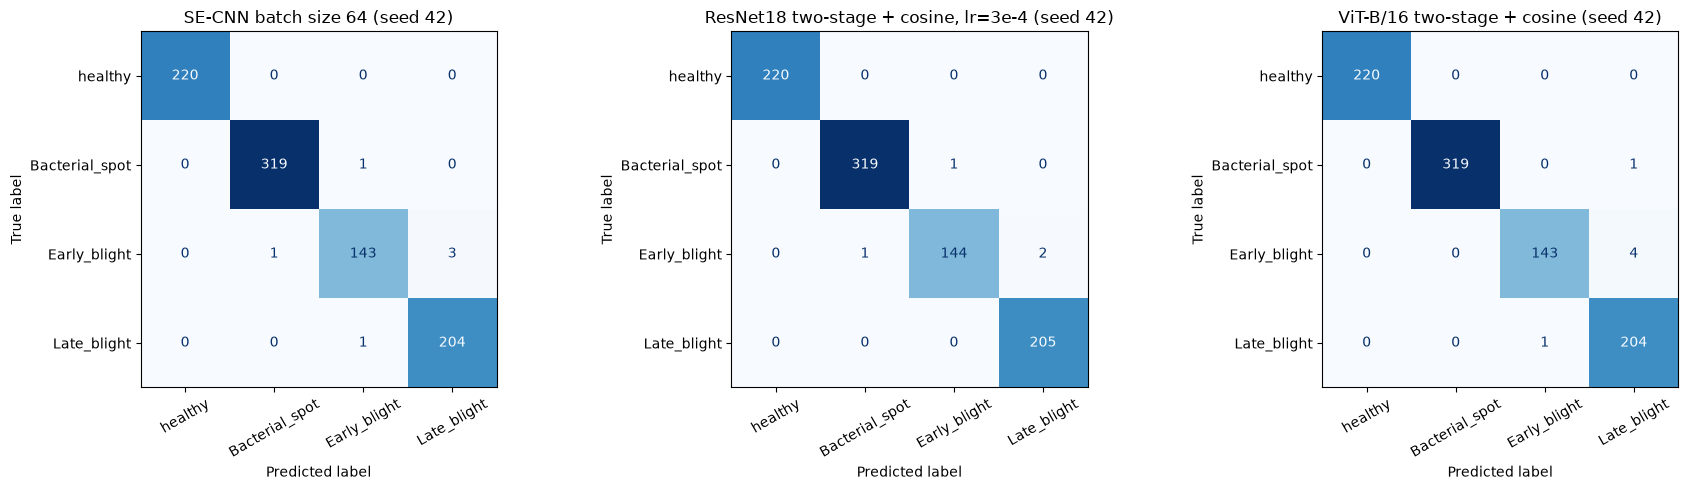

In [21]:
# Detailed report and confusion matrices (seed 42)
for name in FINAL_MODELS:
    print(f"===== {name} (seed {seed0}) =====")
    print(
        classification_report(
            y_test,
            test_probs[(name, seed0)].argmax(1),
            target_names=SHORT_NAMES,
            digits=4,
        )
    )

fig, axes = plt.subplots(1, len(FINAL_MODELS), figsize=(6 * len(FINAL_MODELS), 5))
for ax, name in zip(axes, FINAL_MODELS, strict=True):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        test_probs[(name, seed0)].argmax(1),
        display_labels=SHORT_NAMES,
        cmap="Blues",
        colorbar=False,
        xticks_rotation=30,
        ax=ax,
    )
    ax.set_title(f"{name} (seed {seed0})")
finish("confusion_matrices.png")

### 10.1 How certain are these scores? Bootstrap confidence intervals

Every score above is a single number from one test set. With other leaves in the test set it would be slightly different. We measure how much **without any new training**, using the **bootstrap**: we repeatedly draw a new test set from the existing one and recompute the score.

We draw leaves **with replacement** until the resample is as large as the test set (1,000 times; some leaves appear twice, others not at all), recompute the macro-F1 each time and report the middle 95 % of the values. We resample **whole leaf groups**, not single photos. The photos of one leaf are almost copies of each other, so resampling photos would pretend to have far more independent test items than we really have and give intervals that are too narrow. The interval belongs to the model score averaged over the three training seeds, as in the table above. It covers only the uncertainty from the choice of test leaves; the randomness of the training is shown separately by the standard deviation over seeds.

In [ ]:
# Bootstrap over whole leaf groups (plantdisease/evaluate.py: macro_f1, bootstrap_resamples, bootstrap_f1)
test_groups = data.test_groups  # leaf group of every test image
TEST_RESAMPLES = bootstrap_resamples(leaf_group_members(test_groups))
test_preds = {key: probs.argmax(1) for key, probs in test_probs.items()}
boot_clean = {}  # model -> macro-F1 of every resample
rows = []
for name in FINAL_MODELS:
    preds = [test_preds[(name, seed)] for seed in SEEDS]
    boot_clean[name] = bootstrap_f1(preds, y_test, TEST_RESAMPLES)
    low, high = np.percentile(boot_clean[name], [2.5, 97.5])
    rows.append(
        {
            "model": name,
            "macro-F1": np.mean([macro_f1(y_test, p) for p in preds]),
            "95% interval": f"[{low:.4f}, {high:.4f}]",
            "interval width": high - low,
        }
    )
intervals = pd.DataFrame(rows).set_index("model")
intervals.to_csv(out_path("test_intervals.csv"))
print(
    f"{len(y_test)} test images in {len(np.unique(test_groups))} leaf groups | "
    f"{N_BOOT} bootstrap resamples, whole leaf groups"
)
intervals.round(4)

### 10.2 Is a difference between two models real?

For every pair of models we take the difference of their bootstrap scores. The resamples are identical for all models, so the comparison is paired. The 95 % interval of the difference decides: entirely above 0 means the first model is better, entirely below 0 the second, and an interval that contains 0 means the test set gives **no evidence** of a difference. The interval also shows how large a difference could still be hidden at this test-set size.

In [ ]:
rows = []
for i, name_a in enumerate(FINAL_MODELS):
    for name_b in FINAL_MODELS[i + 1 :]:
        diff, low, high, result = verdict(
            boot_clean[name_a], boot_clean[name_b], names=(name_a, name_b)
        )
        rows.append(
            {
                "model A": name_a,
                "model B": name_b,
                "A - B": diff,
                "95% interval": f"[{low:+.4f}, {high:+.4f}]",
                "differences above this are ruled out": max(abs(low), abs(high)),
                "verdict": result,
            }
        )
paired_clean = pd.DataFrame(rows)
paired_clean.to_csv(out_path("paired_comparison_clean.csv"), index=False)
paired_clean.round(4)

## 11. Compute Trade-offs

Accuracy is not the only criterion. A model for a farmer's phone must also be small and fast. For each final model we measure:
- the number of parameters and the checkpoint size;
- the mean training time per epoch;
- inference latency for a single image and throughput for batches of 64, on the current device after a warm-up.

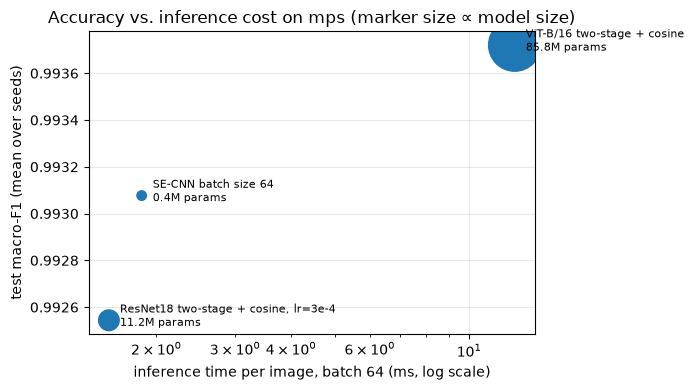

,params (M),size (MB),train s/epoch,epochs,latency bs=1 (ms),ms/image bs=64,test macro-F1
model,,,,,,,
SE-CNN batch size 64,0.4122,1.6648,31.3379,50,2.8441,1.8534,0.9931
"ResNet18 two-stage + cosine, lr=3e-4",11.1786,44.7849,27.5722,16,4.4972,1.5658,0.9925
ViT-B/16 two-stage + cosine,85.8017,343.2554,112.5146,12,16.8297,12.6396,0.9937


In [22]:
rows = []
for name in FINAL_MODELS:
    model = load_model(name, seed0)
    checkpoint = os.path.join(run_path(name, seed0), "best.pt")
    rows.append(
        {
            "model": name,
            "params (M)": count_params(model) / 1e6,
            "size (MB)": os.path.getsize(checkpoint) / 1e6,
            "train s/epoch": np.mean(
                [np.mean(load_history(name, s)["epoch_time"]) for s in SEEDS]
            ),
            "epochs": config_of(name)["epochs"],
            "latency bs=1 (ms)": measure_latency(model, 1),
            "ms/image bs=64": measure_latency(model, 64),
            "test macro-F1": per_seed.loc[per_seed.model == name, "macro_f1"].mean(),
        }
    )
compute = pd.DataFrame(rows).set_index("model")
compute.to_csv(out_path("compute_tradeoffs.csv"))

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(
    compute["ms/image bs=64"], compute["test macro-F1"], s=40 + 4 * compute["size (MB)"]
)
for name, r in compute.iterrows():
    ax.annotate(
        f"{name}\n{r['params (M)']:.1f}M params",
        (r["ms/image bs=64"], r["test macro-F1"]),
        textcoords="offset points",
        xytext=(8, -4),
        fontsize=8,
    )
ax.set_xscale("log")
ax.set_xlabel("inference time per image, batch 64 (ms, log scale)")
ax.set_ylabel("test macro-F1 (mean over seeds)")
ax.set_title(f"Accuracy vs. inference cost on {device.type} (marker size ∝ model size)")
ax.grid(alpha=0.3)
finish("compute_tradeoffs.png")
compute.round(4)

## 12. Error Analysis

### 12.1 Which classes are confused, and how confident are the errors?
We pool the predictions of all seeds and list the most frequent (true → predicted) confusions. We also report the mean confidence of correct and wrong predictions. Confident errors are more dangerous than uncertain ones, because uncertain predictions could be flagged for a human expert.

In [23]:
for name in FINAL_MODELS:
    cm = sum(
        confusion_matrix(
            y_test, test_probs[(name, s)].argmax(1), labels=range(len(CLASSES))
        )
        for s in SEEDS
    )
    np.fill_diagonal(cm, 0)
    pairs = sorted(
        (
            (cm[i, j], SHORT_NAMES[i], SHORT_NAMES[j])
            for i in range(len(CLASSES))
            for j in range(len(CLASSES))
            if cm[i, j]
        ),
        reverse=True,
    )
    conf = np.concatenate([test_probs[(name, s)].max(1) for s in SEEDS])
    wrong = np.concatenate([test_probs[(name, s)].argmax(1) != y_test for s in SEEDS])
    print(
        f"{name}: {cm.sum()} errors over {len(SEEDS)} seeds | mean confidence correct {conf[~wrong].mean():.3f}, wrong {conf[wrong].mean() if wrong.any() else float('nan'):.3f}"
    )
    for count, t, p in pairs[:4]:
        print(f"    {t:15s} -> {p:15s} {count}")

SE-CNN batch size 64: 15 errors over 3 seeds | mean confidence correct 0.994, wrong 0.743
    Early_blight    -> Late_blight     6
    Late_blight     -> Early_blight    4
    Early_blight    -> Bacterial_spot  2
    Bacterial_spot  -> Early_blight    2
ResNet18 two-stage + cosine, lr=3e-4: 18 errors over 3 seeds | mean confidence correct 0.997, wrong 0.723
    Early_blight    -> Late_blight     5
    Bacterial_spot  -> Late_blight     5
    Late_blight     -> Early_blight    3
    Early_blight    -> Bacterial_spot  2
ViT-B/16 two-stage + cosine: 14 errors over 3 seeds | mean confidence correct 0.997, wrong 0.851
    Early_blight    -> Late_blight     7
    Late_blight     -> Early_blight    3
    Bacterial_spot  -> Late_blight     3
    Bacterial_spot  -> Early_blight    1


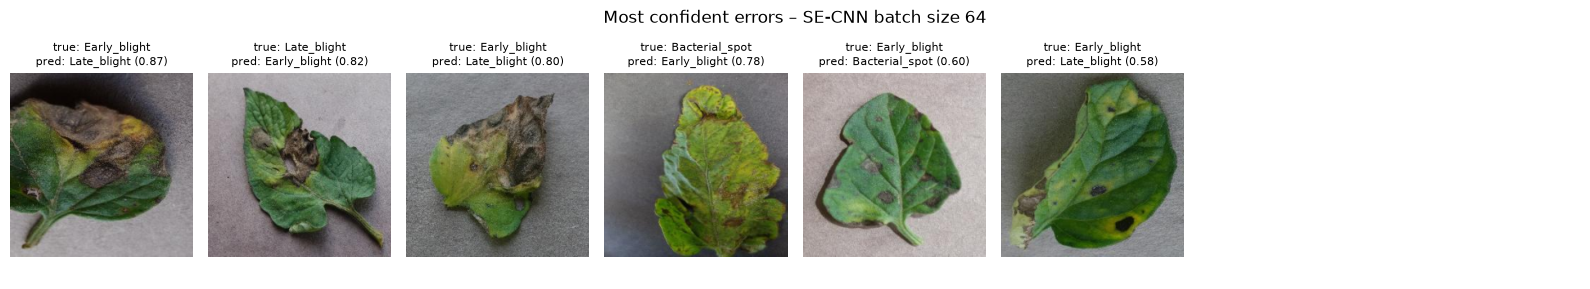

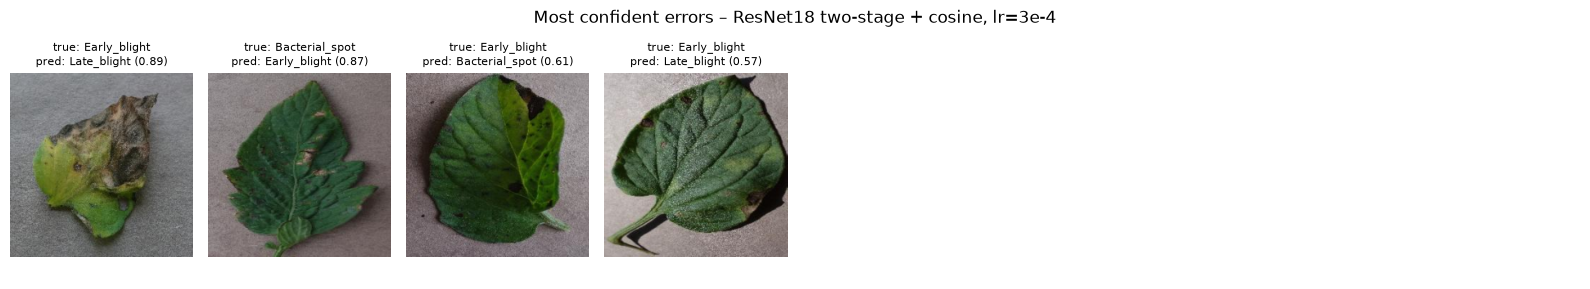

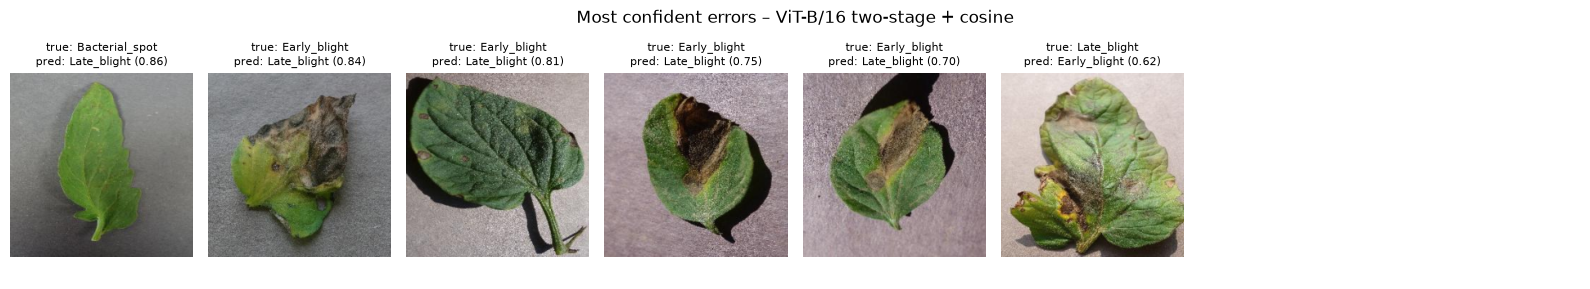

In [24]:
# Misclassified test images (seed 42), sorted by confidence (most confident errors first)
for name in FINAL_MODELS:
    probs = test_probs[(name, seed0)]
    wrong = np.where(probs.argmax(1) != y_test)[0]
    wrong = wrong[np.argsort(-probs[wrong].max(1))][:8]
    if len(wrong) == 0:
        print(f"{name}: no misclassified test images")
        continue
    fig, axes = plt.subplots(1, 8, figsize=(16, 2.9))
    for ax in axes:
        ax.axis("off")
    for ax, i in zip(axes, wrong, strict=False):
        ax.imshow(data.images[data.test_idx[i]].permute(1, 2, 0))
        ax.set_title(
            f"true: {SHORT_NAMES[y_test[i]]}\npred: {SHORT_NAMES[probs[i].argmax()]} ({probs[i].max():.2f})",
            fontsize=8,
        )
    fig.suptitle(f"Most confident errors - {name}")
    finish()

### 12.2 Grad-CAM: where do the CNNs look?
Grad-CAM (Selvaraju et al., 2017) weights the feature maps of the last convolutional layer by the average gradient of the predicted class score. The result is a heat map of the image regions that drove the decision. If a model is right for the right reasons, the heat map lies on the **lesions**. If it lies on the **background**, the model may be using a shortcut. We show the same test images (3 correct, 3 misclassified by the CNN) for the custom CNN and ResNet18. Grad-CAM needs convolutional feature maps, so the ViT is not shown here.

The Grad-CAM implementation is `grad_cam` in `plantdisease/evaluate.py`.

/Users/ethan_sun/daai_projects/COMP7015_AI_Group_Project4/.venv/lib/python3.11/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


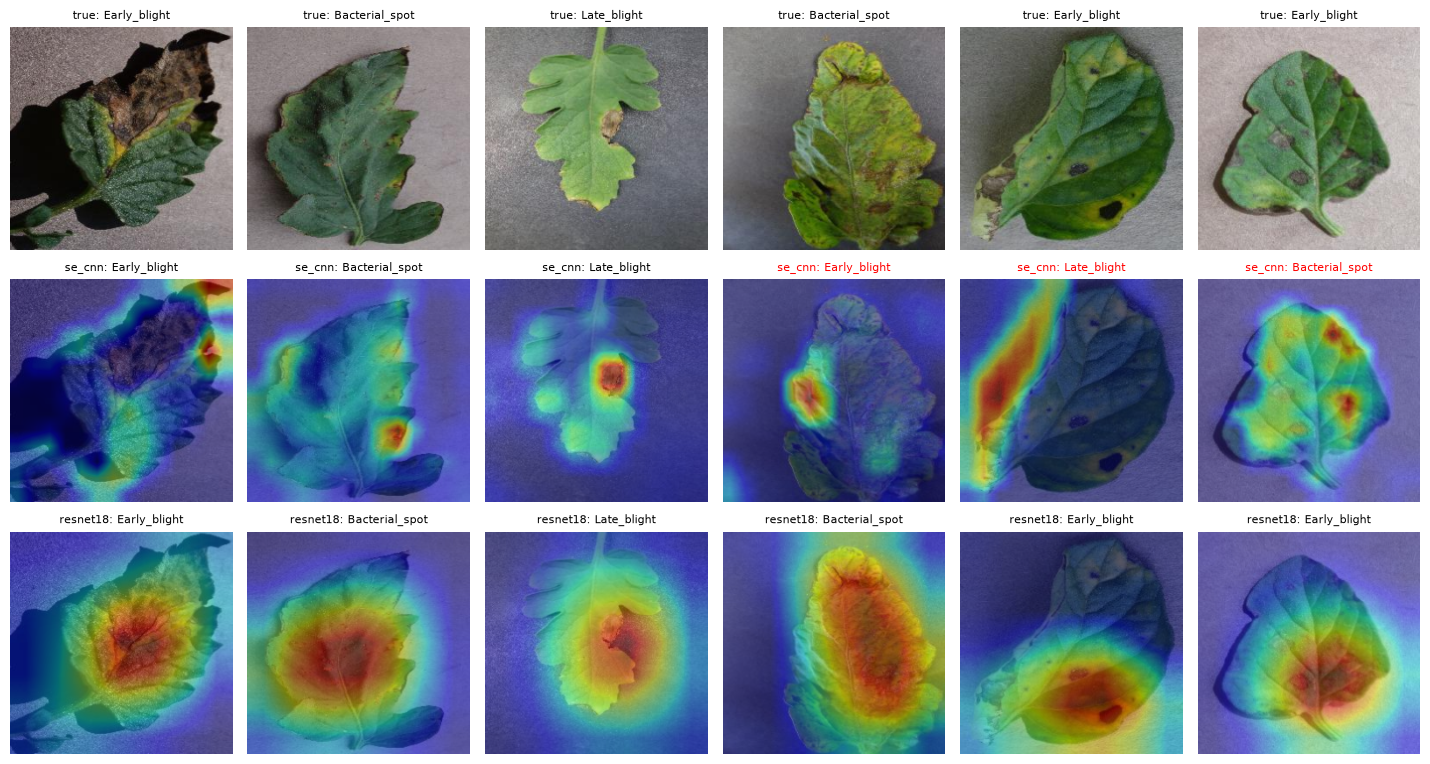

In [25]:
cnn_pred = test_probs[(BEST_CNN, seed0)].argmax(1)
rng_cam = np.random.default_rng(0)
examples = np.concatenate(
    [
        rng_cam.choice(np.where(cnn_pred == y_test)[0], 3, replace=False),
        np.where(cnn_pred != y_test)[0][:3],
    ]
)
images = data.images[data.test_idx[examples]]

cam_models = [BEST_CNN, BEST_RESNET]
fig, axes = plt.subplots(
    len(cam_models) + 1,
    len(examples),
    figsize=(2.4 * len(examples), 2.6 * (len(cam_models) + 1)),
)
for col, i in enumerate(examples):
    axes[0, col].imshow(images[col].permute(1, 2, 0))
    axes[0, col].set_title(f"true: {SHORT_NAMES[y_test[i]]}", fontsize=8)
for row, name in enumerate(cam_models, start=1):
    cams = grad_cam_images(name, seed0, images)
    preds = test_probs[(name, seed0)].argmax(1)
    for col, i in enumerate(examples):
        axes[row, col].imshow(images[col].permute(1, 2, 0))
        axes[row, col].imshow(cams[col], cmap="jet", alpha=0.45)
        axes[row, col].set_title(
            f"{config_of(name)['arch']}: {SHORT_NAMES[preds[i]]}",
            fontsize=8,
            color="black" if preds[i] == y_test[i] else "red",
        )
for ax in axes.flat:
    ax.axis("off")
finish("grad_cam.png")